# Ödev 6 EK çalışma

## 1)
### Tip 2 Filtre

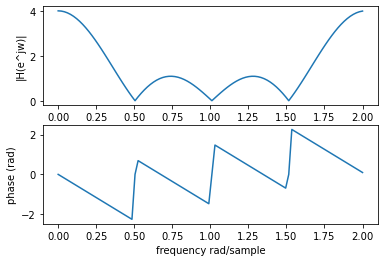

In [24]:
# As usual, we begin with importing necessary libraries and functions  
import numpy as np # for using basic array functions  
import matplotlib.pyplot as plt # for this example, it may not be necessary  
# the main package for signal processing is called "scipy" and we will use u "signal" sub-package  
import scipy.signal as sgnl  
from scipy.fftpack import fft, ifft  
# alternative syntax: from scipy import signal as sgnl  
N = 100
hn = np.ones(4)  
Hw = (fft(hn, N))  
w = np.linspace(0, 2*np.pi,N)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, Hw_mag) , plt.ylabel('|H(e^jw)|') 
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('phase (rad)'), plt.xlabel('frequency rad/sample')
plt.show()



Filtre alçak geçirendir 0 frekansıdaki bileşeni 4 kat yükseltir. Yani DC kazancı 4 tür. 0.5 pi de 0 rı vardır. 0.5 pi 1pi arası yine geirir ama 0 0.5 pi aralığına göre 4 kat daha zayıftır. Bu filte nin 0.5pi de ve pi de 0 rı var.<br>
Filre linear faza sahiptir.

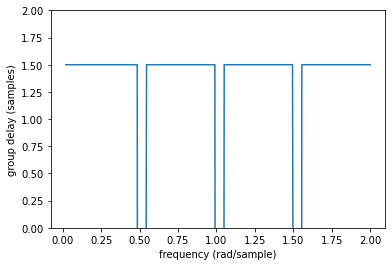

In [25]:
tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.ylim([0,2])
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()


Bu sistemde grup gecikmesi 1.5 olarak görülmektedir.

In [26]:

# coding: utf-8

# In[ ]:

# Copyright (c) 2020 Hasan Huseyin Sonmez
#
# The following code implements a pole-zero diagram for discrete-time signal/systems
# It has been written to mimic the "zplane" function of Mathworks' MATLAB software.
# it is aimed as a supplementary tool to be used in
# ELM368 Fundamentals of Digital Signal Processing-laboratory course.
# Gebze Technical University, Kocaeli, Turkey
#
# The function parameters are:
#     Input:
#            b : the numerator coefficients of the discrete-time signal/system
#            a : the denominator coefficients of the discrete-time signal/system
#


# In[29]:

# import the necessary libraries
import numpy as np              # for using basic array functions
import matplotlib.pyplot as plt # for this example, it may not be necessary

# the main package for signal processing is called "scipy" and we will use "signal" sub-package
import scipy.signal as sgnl 
# alternative syntax: from scipy import signal as sgnl

def zplane(b,a):

	# Input: numerator and denominator coefficients:
	zeross,poless,k = sgnl.tf2zpk(b, a)
	if not zeross.size:
		zeross = np.zeros(len(poless))
		
	if not poless.size:
		poless = np.zeros(len(zeross))

	tol = 1e-4

	real_p = np.real(poless).copy()
	real_z = np.real(zeross).copy()
	imag_p = np.imag(poless).copy()
	imag_z = np.imag(zeross).copy()

	if not real_z.size:
		real_z[abs(real_z) < tol] = 0
	if not imag_z.size:
		imag_z[abs(imag_z) < tol] = 0
	if not real_p.size:
		real_p[abs(real_p) < tol] = 0
	if not imag_p.size:
		imag_p[abs(imag_p) < tol] = 0

	z = np.round(real_z,2) + 1j*np.round(imag_z,2)
	p = np.round(real_p,2) + 1j*np.round(imag_p,2)

	# plot the unit circle
	N = 128
	m = np.arange(0,N,1)
	unitCircle = np.exp(1j*m*2*np.pi/N)

	plt.figure()
	plt.plot(np.real(unitCircle), np.imag(unitCircle), 'b--', linewidth=0.3)
	plt.xlabel('Real Part'), plt.ylabel('Imaginary Part')

	# calculate the plot limits
	Cz, z_counts = np.unique(z, return_counts=True)
	Cp, p_counts = np.unique(p, return_counts=True)

	zz = [idx1 for idx1, valz in enumerate(z_counts) if valz > 1]
	pp = [idx2 for idx2, valp in enumerate(p_counts) if valp > 1]
	zval = z_counts[zz]
	pval = p_counts[pp]
	zs = Cz[zz]
	ps = Cp[pp]

	real_roots = np.concatenate((np.real(p),np.real(z)))
	imag_roots = np.concatenate((np.imag(p),np.imag(z)))

	# adjust plot limits
	xlower = min(-1, min(real_roots)) - 0.3
	xupper = max(1,  max(real_roots)) + 0.3
	ylower = min(-1, min(imag_roots)) - 0.3
	yupper = max(1,  max(imag_roots)) + 0.3
	plt.xlim(xlower, xupper), plt.ylim(ylower, yupper)

	# plot axes
	Xaxis = np.arange(xlower, xupper, 0.1)
	Yaxis = np.arange(ylower, yupper, 0.1)
	plt.plot(np.real(Xaxis), np.imag(Xaxis), 'b--', linewidth=0.3)
	plt.plot(np.imag(Yaxis), np.real(Yaxis), 'b--', linewidth=0.3)

	# plot poles and zeros
	plt.plot(np.real(z), np.imag(z), 'ro',  markerfacecolor = 'none')
	plt.plot(np.real(p), np.imag(p), 'rx')

	if zz:
		txtz = str(zval)[1:-1]
		plt.annotate(txtz, xy=(np.real(zs)+0.1,np.imag(zs)+0.1))
		
	if pp:
		txtp = str(pval)[1:-1]
		plt.annotate(txtp, xy=(np.real(ps)+0.1,np.imag(ps)+0.1))

	plt.grid()
	plt.show()


# In[ ]:





sıfırlar, z: [-1.00000000e+00+0.j -1.11022302e-16+1.j -1.11022302e-16-1.j]
kutuplar, p: []
kazanc, k: 1.0


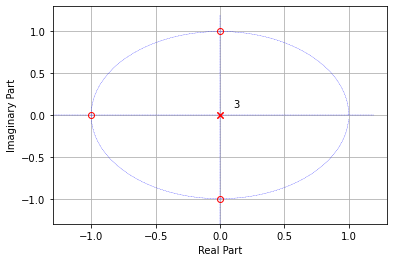

In [27]:
z, p, k = sgnl.tf2zpk(hn, 1) 
print("sıfırlar, z:", z) 
print("kutuplar, p:", p) 
print("kazanc, k:", k)
zplane(hn,1)


Birim çember üzerinde z = -1 , z = -j, z = +j de 0rlar vardır. birim çember üzerinde z = e^jw olduğundan. pi/2 ve pi de 0 rı olduğu açıkça gözükmektedir. Bu da frekans spektrumunda filtrenin yüksek geçiren olmadığını açıkça gösterir.

### Tip 1 Filtre

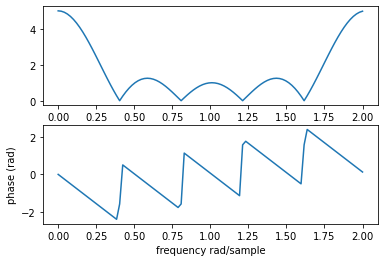

In [28]:
# As usual, we begin with importing necessary libraries and functions  
import numpy as np # for using basic array functions  
import matplotlib.pyplot as plt # for this example, it may not be necessary  
# the main package for signal processing is called "scipy" and we will use u "signal" sub-package  
import scipy.signal as sgnl  
from scipy.fftpack import fft, ifft  
# alternative syntax: from scipy import signal as sgnl  
N = 100
hn = np.ones(5)  
Hw = (fft(hn, N))  
w = np.linspace(0, 2*np.pi,N)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, Hw_mag)  
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('phase (rad)'), plt.xlabel('frequency rad/sample')
plt.show()



Bu filtre alçak geçirendir. yaklaşık 0.4pi ve 0.8pi de 0 rı olduğu gözükmektedir. Düşük frekansları güçlendirir. Fazı lineardir.

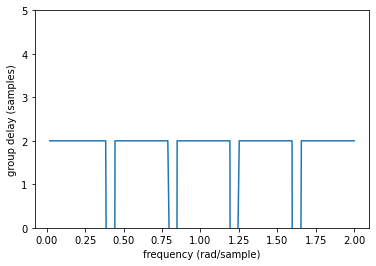

In [29]:
tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.ylim([0,5])
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()


Faz linear olduğundan grup gecikmesi de sabit ve 2 olarak gözükmektedir.

sıfırlar, z: [ 0.30901699+0.95105652j  0.30901699-0.95105652j -0.80901699+0.58778525j
 -0.80901699-0.58778525j]
kutuplar, p: []
kazanc, k: 1.0


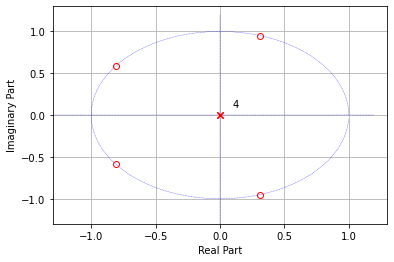

In [30]:
z, p, k = sgnl.tf2zpk(hn, 1) 
print("sıfırlar, z:", z) 
print("kutuplar, p:", p) 
print("kazanc, k:", k)
zplane(hn,1)


In [31]:
Zphase = np.angle(z)/np.pi
print(Zphase)

[ 0.4 -0.4  0.8 -0.8]


Burdan filtrenin 0.4 ve 0.8 pi de 0ları olduğu açıkça gözükmektedir

### Tip 4 Filtre

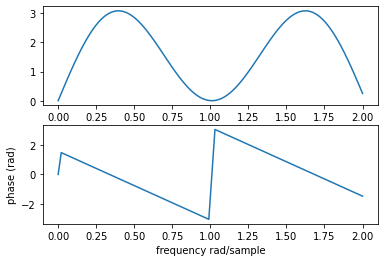

In [32]:
# As usual, we begin with importing necessary libraries and functions  
import numpy as np # for using basic array functions  
import matplotlib.pyplot as plt # for this example, it may not be necessary  
# the main package for signal processing is called "scipy" and we will use u "signal" sub-package  
import scipy.signal as sgnl  
from scipy.fftpack import fft, ifft  
# alternative syntax: from scipy import signal as sgnl  
N = 100
hn =[1,1,-1,-1]
Hw = (fft(hn, N))  
w = np.linspace(0, 2*np.pi,N)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, Hw_mag)  
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('phase (rad)'), plt.xlabel('frequency rad/sample')
plt.show()



Filtrenin 0 da ve pi de 0 rı vardır.Bu yüzden ne yüksek geçiren ne alçak geçiren olabimektedir. Burdaki filtre bant geçirendir .linear faza sahiptir.

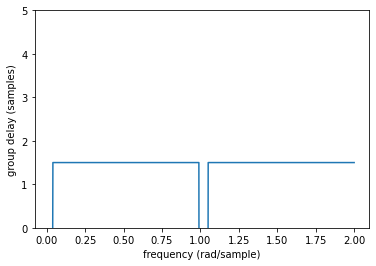

In [33]:
tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.ylim([0,5])
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()


Grup gecikmesi 1.5 tur

sıfırlar, z: [ 1.+0.00000000e+00j -1.+1.41530425e-09j -1.-1.41530425e-09j]
kutuplar, p: []
kazanc, k: 1.0


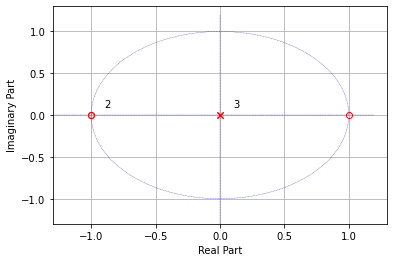

In [34]:
z, p, k = sgnl.tf2zpk(hn, 1) 
print("sıfırlar, z:", z) 
print("kutuplar, p:", p) 
print("kazanc, k:", k)
zplane(hn,1)


z = 1 ve z = -1 de birim çemberin üzerinde sıfırlarının olduğu görülmektedir. buda demek oluyorki 0 da ve pi de filtrenin 0 rı var.

### Tip 3 Filtre

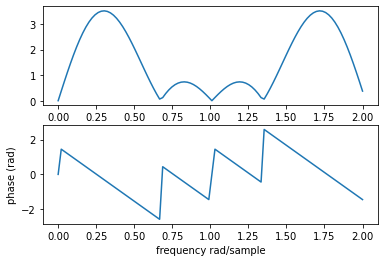

In [35]:
# As usual, we begin with importing necessary libraries and functions  
import numpy as np # for using basic array functions  
import matplotlib.pyplot as plt # for this example, it may not be necessary  
# the main package for signal processing is called "scipy" and we will use u "signal" sub-package  
import scipy.signal as sgnl  
from scipy.fftpack import fft, ifft  
# alternative syntax: from scipy import signal as sgnl  
N = 100
hn =[1,1,0,-1,-1]
Hw = (fft(hn, N))  
w = np.linspace(0,2* np.pi,N)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, Hw_mag)  
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('phase (rad)'), plt.xlabel('frequency rad/sample')
plt.show()




Filtrenin 0 da, 0.66pide ve pi de 0 rı vardır. Alçak geçiren gibi davranmaktadır.

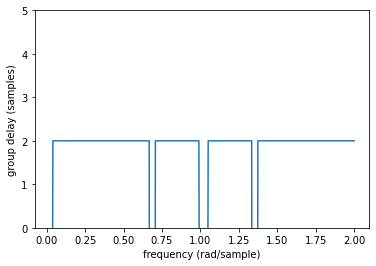

In [36]:
tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.ylim([0,5])
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()


sıfırlar, z: [ 1. +0.j        -0.5+0.8660254j -0.5-0.8660254j -1. +0.j       ]
kutuplar, p: []
kazanc, k: 1.0


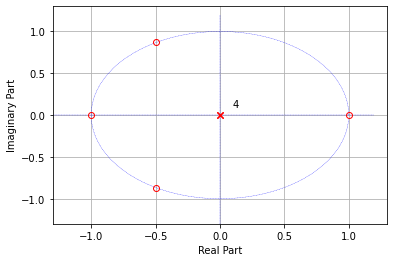

In [37]:
z, p, k = sgnl.tf2zpk(hn, 1) 
print("sıfırlar, z:", z) 
print("kutuplar, p:", p) 
print("kazanc, k:", k)
zplane(hn,1)


In [38]:
Zphase = np.angle(z)/np.pi
print(Zphase)

[ 0.          0.66666667 -0.66666667  1.        ]


kutuplar birim çember üzerindedir fazları hesaplandığında frekans cevabından de gördüğümüz gibi Filtrenin 0 da, 0.66pide ve pi de 0 rı vardır.

## 2)


### Tip 2 filtre

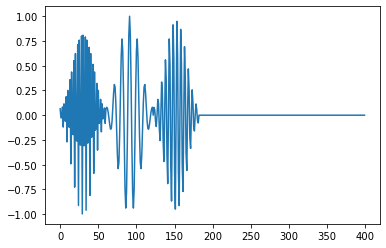

In [51]:
# As usual, we begin with importing necessary libraries and functions  
import numpy as np # for using basic array functions  
import matplotlib.pyplot as plt # for this example, it may not be necessary  
# the main package for signal processing is called "scipy" and we will use \leftrightarrow"signal" sub-package  
import scipy.signal as sgnl  
from scipy.fftpack import fft, ifft  
# alternative syntax: from scipy import signal as sgnl   
# WE NEED TO IMPORT THE CUSTOM (USER DEFINED) FUNCTION AS WELL, IN ORDER TO USE  
import SystemFunction  
# Generate the individual components and the input signal  
N = 400 # total number of samples in the input signal  
M =60 # size of the window function (and sample length of the frequency
n = np.arange(0, M+1, 1) # index vector of M+1 points  
wn = 0.54-0.46*np.cos(2*np.pi*n/M) # window function (Hamming window)  
# the components  
x1 = wn*np.cos(0.2*np.pi*n) # component with w1 = 0.2*pi frequency  
x2 = wn*np.cos(0.4*np.pi*n - np.pi/2) # component with w1 = 0.4*pi frequency  
x3 = wn*np.cos(0.8*np.pi*n - np.pi/5) # component with w1 = 0.8*pi frequency  
xn = np.concatenate((x3, x1, x2, np.zeros(N-3*len(n))), axis=None)  
plt.figure()
plt.plot(xn)
plt.show()


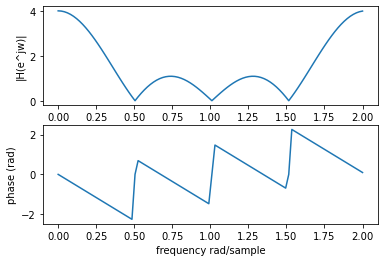

In [55]:
N = 100
hn = np.ones(4)  
Hw = (fft(hn, N))  
w = np.linspace(0, 2*np.pi,N)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, Hw_mag) , plt.ylabel('|H(e^jw)|') 
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('phase (rad)'), plt.xlabel('frequency rad/sample')
plt.show()

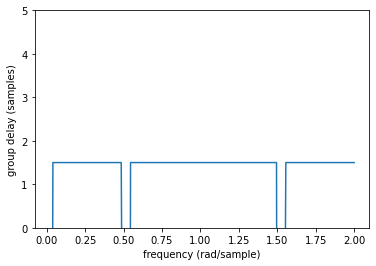

In [53]:
tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.ylim([0,5])
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()


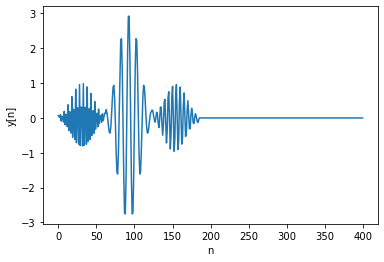

In [54]:
yn = sgnl.lfilter(hn,1,xn) 
plt.figure()
plt.ylabel('y[n]')
plt.xlabel('n')
plt.plot(yn)
plt.show()

0.2 pi frekanslı sinyal güçlendi. 0.4pi ve 0.8pi frekansına sahip sinyallerde bir değişim pek olmadı. Çünkü 0.2pi frekansında kazanç üç civarı iken 0.4pi ve 0.8pi frekanslarında 1 civarı olduğu frekans spektrumundan açıkça görülmektedir

## Tip 1 Filtre ile

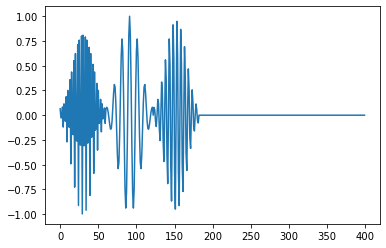

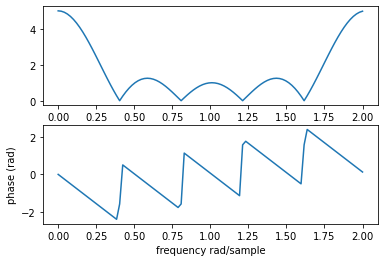

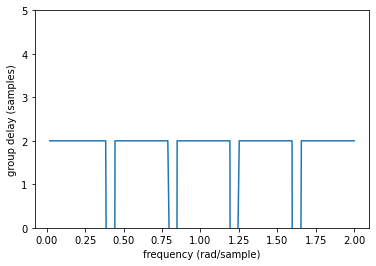

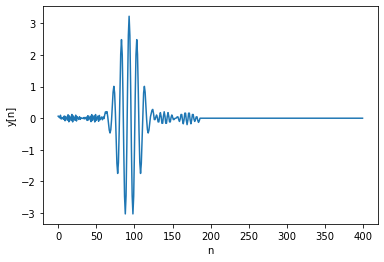

In [43]:
N = 400 # total number of samples in the input signal  
M =60 # size of the window function (and sample length of the frequency
n = np.arange(0, M+1, 1) # index vector of M+1 points  
wn = 0.54-0.46*np.cos(2*np.pi*n/M) # window function (Hamming window)  
# the components  
x1 = wn*np.cos(0.2*np.pi*n) # component with w1 = 0.2*pi frequency  
x2 = wn*np.cos(0.4*np.pi*n - np.pi/2) # component with w1 = 0.4*pi frequency  
x3 = wn*np.cos(0.8*np.pi*n - np.pi/5) # component with w1 = 0.8*pi frequency  
xn = np.concatenate((x3, x1, x2, np.zeros(N-3*len(n))), axis=None)  
plt.figure()
plt.plot(xn)
plt.show()

N = 100
hn = np.ones(5)  
Hw = (fft(hn, N))  
w = np.linspace(0,2* np.pi,N)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, Hw_mag)  
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('phase (rad)'), plt.xlabel('frequency rad/sample')
plt.show()


tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.ylim([0,5])
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()

yn = sgnl.lfilter(hn,1,xn) 
plt.figure()
plt.ylabel('y[n]')
plt.xlabel('n')
plt.plot(yn)
plt.show()


Filtreden sadece 0.2pi frekanslı olan sinyal geçti diğer sinyaller yaklaşık olarak sıfırlandı. 0.2pi deki sinayl güçlendi, çünkü genlik spektrumunda w= 0.2pi yaklaşık 3 tür. 0.4pi ve 0.8pi frekanslarının yakında ise filtrenin sıfırları bulunmaktadır.

## Tip 4 filtre ile

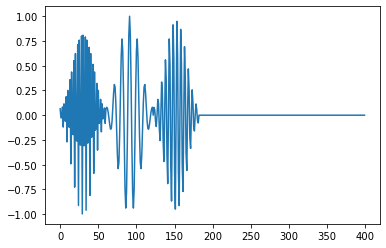

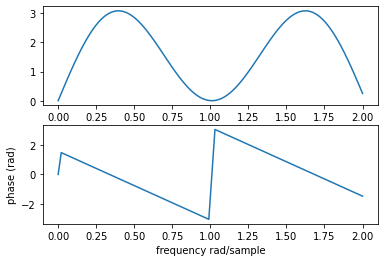

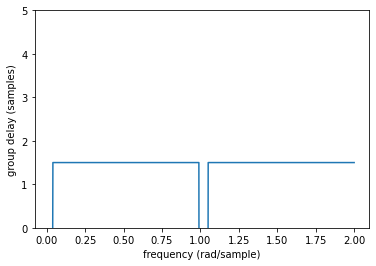

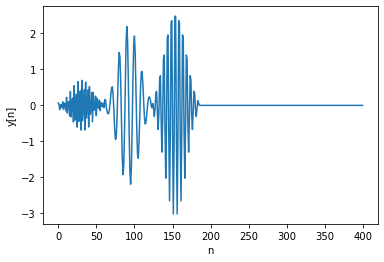

In [44]:
N = 400 # total number of samples in the input signal  
M =60 # size of the window function (and sample length of the frequency
n = np.arange(0, M+1, 1) # index vector of M+1 points  
wn = 0.54-0.46*np.cos(2*np.pi*n/M) # window function (Hamming window)  
# the components  
x1 = wn*np.cos(0.2*np.pi*n) # component with w1 = 0.2*pi frequency  
x2 = wn*np.cos(0.4*np.pi*n - np.pi/2) # component with w1 = 0.4*pi frequency  
x3 = wn*np.cos(0.8*np.pi*n - np.pi/5) # component with w1 = 0.8*pi frequency  
xn = np.concatenate((x3, x1, x2, np.zeros(N-3*len(n))), axis=None)  
plt.figure()
plt.plot(xn)
plt.show()

N = 100
hn =[1,1,-1,-1]
Hw = (fft(hn, N))  
w = np.linspace(0, 2*np.pi,N)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, Hw_mag)  
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('phase (rad)'), plt.xlabel('frequency rad/sample')
plt.show()


tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.ylim([0,5])
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()

yn = sgnl.lfilter(hn,1,xn) 
plt.figure()
plt.ylabel('y[n]')
plt.xlabel('n')
plt.plot(yn)
plt.show()


Filtre bant geçiren filtredir . En çok 0.4 pi frekansına sahip olan sinayal güçlendi sonra ise 0.2pi , en az genliği sahip sinyal ise 0.8pi frekansına sahip sinayl oldu

## Tip 3 filtre ile

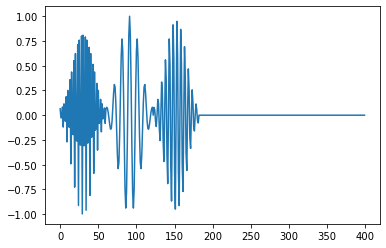

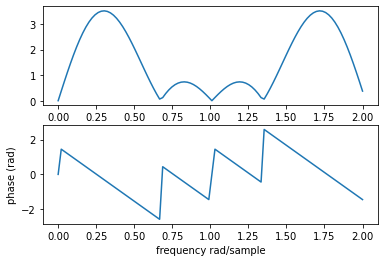

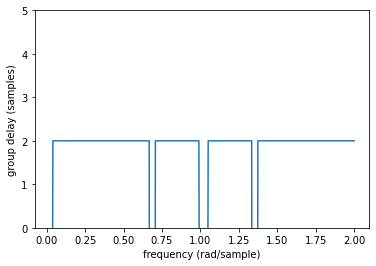

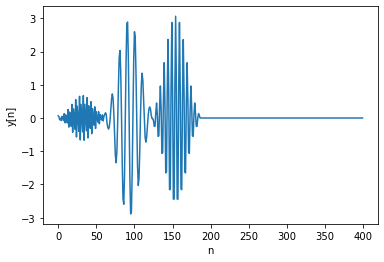

In [45]:
N = 400 # total number of samples in the input signal  
M =60 # size of the window function (and sample length of the frequency
n = np.arange(0, M+1, 1) # index vector of M+1 points  
wn = 0.54-0.46*np.cos(2*np.pi*n/M) # window function (Hamming window)  
# the components  
x1 = wn*np.cos(0.2*np.pi*n) # component with w1 = 0.2*pi frequency  
x2 = wn*np.cos(0.4*np.pi*n - np.pi/2) # component with w1 = 0.4*pi frequency  
x3 = wn*np.cos(0.8*np.pi*n - np.pi/5) # component with w1 = 0.8*pi frequency  
xn = np.concatenate((x3, x1, x2, np.zeros(N-3*len(n))), axis=None)  
plt.figure()
plt.plot(xn)
plt.show()

N = 100
hn =[1,1,0,-1,-1]
Hw = (fft(hn, N))  
w = np.linspace(0, 2*np.pi,N)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, Hw_mag)  
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('phase (rad)'), plt.xlabel('frequency rad/sample')
plt.show()


tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.ylim([0,5])
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()

yn = sgnl.lfilter(hn,1,xn) 
plt.figure()
plt.ylabel('y[n]')
plt.xlabel('n')
plt.plot(yn)
plt.show()


Filtrenin yapısından dolayı en çok 0.4 pi frekansına sahip olan sinayal güçlendi sonra ise 0.2pi , en az genliği sahip sinyal ise 0.8pi frekansına sahip sinayl oldu

### Bant geçiren FIR filtre tasarımı (Blackman)
(0.3 * pi , 0.6 * pi) arası geçirecek şekilde tasarlanmıştır
Kullanılan yöntem Blackman derecesi N = 40 


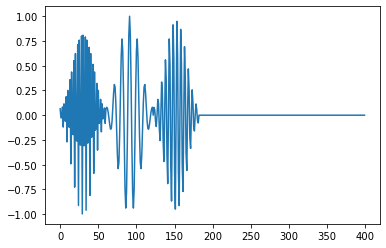

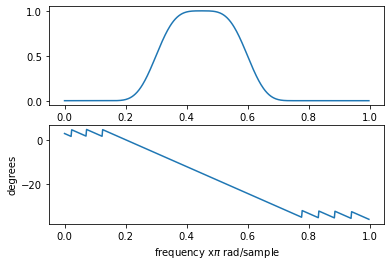

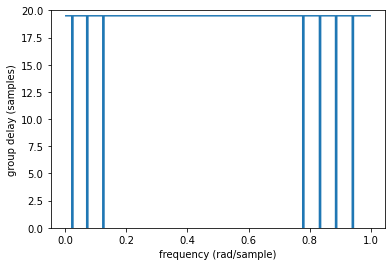

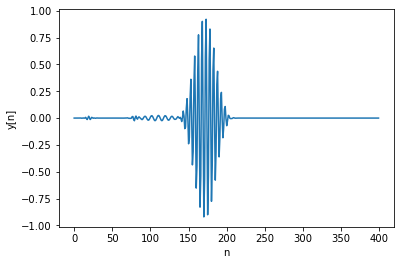

In [46]:
# As usual, we begin with importing necessary libraries and functions  
import numpy as np # for using basic array functions  
import matplotlib.pyplot as plt # for this example, it may not be necessary  
# the main package for signal processing is called "scipy" and we will use "signal" sub-package  
import scipy.signal as sgnl  
from scipy.fftpack import fft, ifft  
# alternative syntax: from scipy import signal as sgnl  
# to read .csv data file  
from scipy.io import loadmat  
N = 400 # total number of samples in the input signal  
M =60 # size of the window function (and sample length of the frequency
n = np.arange(0, M+1, 1) # index vector of M+1 points  
wn = 0.54-0.46*np.cos(2*np.pi*n/M) # window function (Hamming window)  
# the components  
x1 = wn*np.cos(0.2*np.pi*n) # component with w1 = 0.2*pi frequency  
x2 = wn*np.cos(0.4*np.pi*n - np.pi/2) # component with w1 = 0.4*pi frequency  
x3 = wn*np.cos(0.8*np.pi*n - np.pi/5) # component with w1 = 0.8*pi frequency  
xn = np.concatenate((x3, x1, x2, np.zeros(N-3*len(n))), axis=None)  
plt.figure()
plt.plot(xn)
plt.show()



# importing an IIR filter  
filter_data = loadmat('blackman_bandpass.mat') # load the filter obtained from  pyfda  
Coeffs = filter_data['ba'].astype(float) # get the coefficients and  <convert them to float (from string)  
#print(Coeffs)
b = Coeffs[:,0] # first column is b  
a = 1


w, Hw = sgnl.freqz(b,a)  
Hw_mag = abs(Hw)  
N = len(Hw)*2
Hw_phs = np.unwrap(np.angle(Hw))  
fig, (ax1, ax2) = plt.subplots(2)  
ax1.plot(w/np.pi, Hw_mag)  
ax2.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()

tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.ylim([0,20])
plt.plot(w[1::]/np.pi, tau_w)  
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()

yn = sgnl.lfilter(b,a,xn) 
plt.figure()
plt.ylabel('y[n]')
plt.xlabel('n')
plt.plot(yn)
plt.show()


Filtre bir bant geçiren filtredir 0.4 pi geçirdiği bantın içi.nde olduğundan çıkışa başarılı bir şekilde aktarılır. 20 örenk kadar gecikme oluşmaktadır.

### Bant geçiren FIR filtre tasarımı (Barthann)
Geçirme frekansı (0.2 * pi, 0.5 * pi) arasındadır. Filtere derecesi 30 'dur.



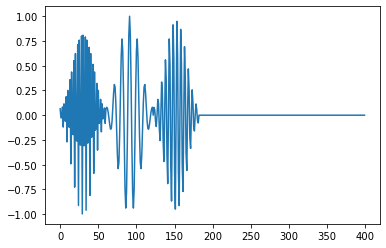

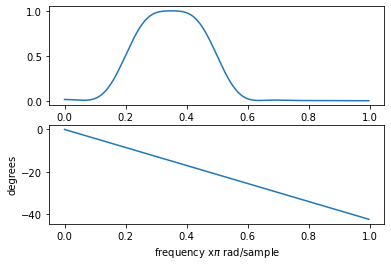

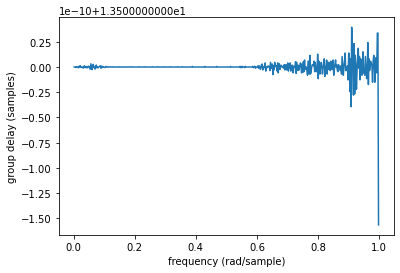

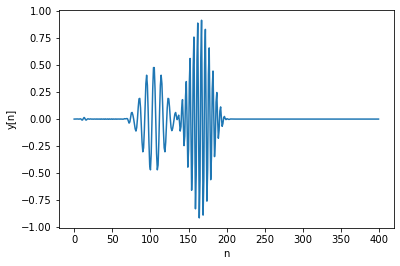

In [47]:
N = 400 # total number of samples in the input signal  
M =60 # size of the window function (and sample length of the frequency
n = np.arange(0, M+1, 1) # index vector of M+1 points  
wn = 0.54-0.46*np.cos(2*np.pi*n/M) # window function (Hamming window)  
# the components  
x1 = wn*np.cos(0.2*np.pi*n) # component with w1 = 0.2*pi frequency  
x2 = wn*np.cos(0.4*np.pi*n - np.pi/2) # component with w1 = 0.4*pi frequency  
x3 = wn*np.cos(0.8*np.pi*n - np.pi/5) # component with w1 = 0.8*pi frequency  
xn = np.concatenate((x3, x1, x2, np.zeros(N-3*len(n))), axis=None)  
plt.figure()
plt.plot(xn)
plt.show()

# importing an IIR filter  
filter_data = loadmat('bandpass_barthann.mat') # load the filter obtained from  pyfda  
Coeffs = filter_data['ba'].astype(float) # get the coefficients and  <convert them to float (from string)  
#print(Coeffs)
b = Coeffs[:,0] # first column is b  
a = 1


w, Hw = sgnl.freqz(b,a)  
Hw_mag = abs(Hw)  
N = len(Hw)*2

Hw_phs = np.unwrap(np.angle(Hw))  
fig, (ax1, ax2) = plt.subplots(2)  
ax1.plot(w/np.pi, Hw_mag)  
ax2.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()


tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()

yn = sgnl.lfilter(b,a,xn) 
plt.figure()
plt.ylabel('y[n]')
plt.xlabel('n')
plt.plot(yn)
plt.show()


Filtrre yine bir bant geçiren filtredir. Ama bu sefer 0.2 pilik sinayl zayıflayarak filtreden geçebilmektedir 0.2pi kesim frekansı olduğundan

## Alçak geçiren Filtre tasarımı Hann (0.3*pi kesim frekansı)

0.3*pi kesim frekansı olarak seçildi hann filtresi, derecesi 40'tır





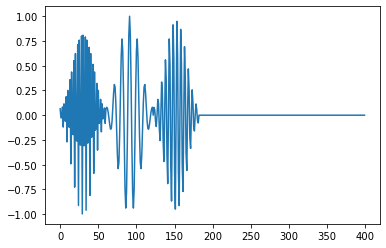

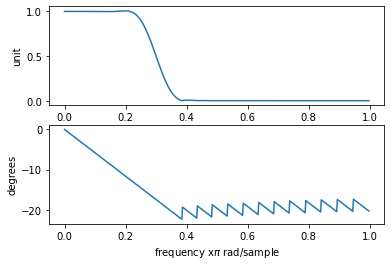

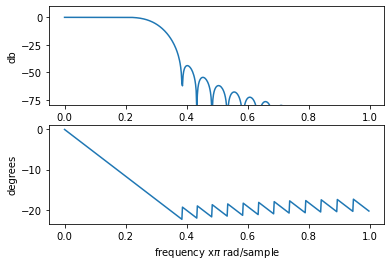

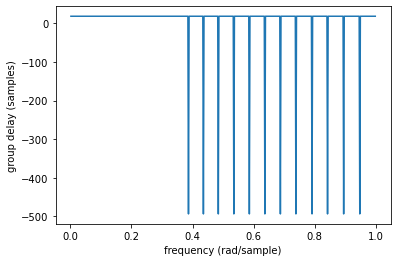

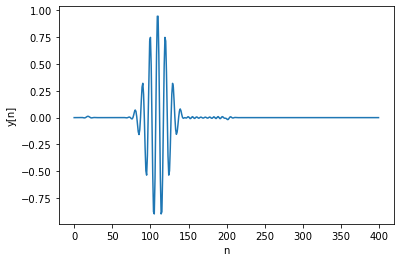

In [56]:

N = 400 # total number of samples in the input signal  
M =60 # size of the window function (and sample length of the frequency
n = np.arange(0, M+1, 1) # index vector of M+1 points  
wn = 0.54-0.46*np.cos(2*np.pi*n/M) # window function (Hamming window)  
# the components  
x1 = wn*np.cos(0.2*np.pi*n) # component with w1 = 0.2*pi frequency  
x2 = wn*np.cos(0.4*np.pi*n - np.pi/2) # component with w1 = 0.4*pi frequency  
x3 = wn*np.cos(0.8*np.pi*n - np.pi/5) # component with w1 = 0.8*pi frequency  
xn = np.concatenate((x3, x1, x2, np.zeros(N-3*len(n))), axis=None)  
plt.figure()
plt.plot(xn)
plt.show()
# importing an IIR filter  
filter_data = loadmat('lowpass_hann.mat') # load the filter obtained from  pyfda  
Coeffs = filter_data['ba'].astype(float) # get the coefficients and  <convert them to float (from string)  
#print(Coeffs)
b = Coeffs[:,0] # first column is b  
a = 1


w, Hw = sgnl.freqz(b,a)  
N = len(Hw)*2
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, Hw_mag)  , plt.ylabel("unit")
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()



w, Hw = sgnl.freqz(b,a)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, 20*np.log10(Hw_mag))  , plt.ylabel("db")
plt.ylim([-80,10])
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()

tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()

yn = sgnl.lfilter(b,a,xn) 
plt.figure()
plt.ylabel('y[n]')
plt.xlabel('n')
plt.plot(yn)
plt.show()


### Butterwoth low pass IIR filter 
fc = 0.3*pi filter degree = 20

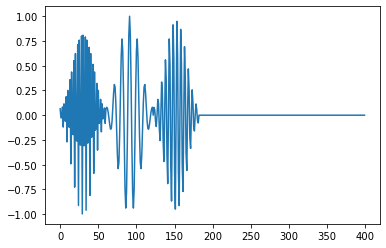

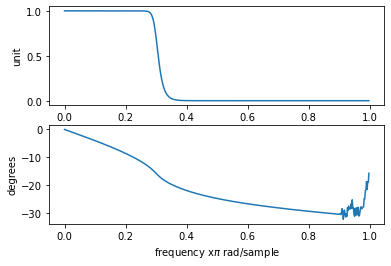

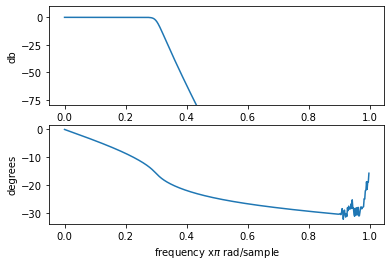

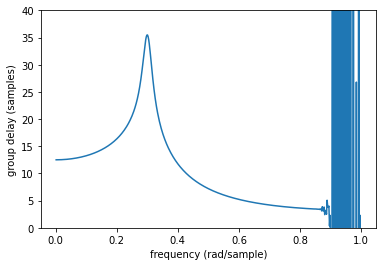

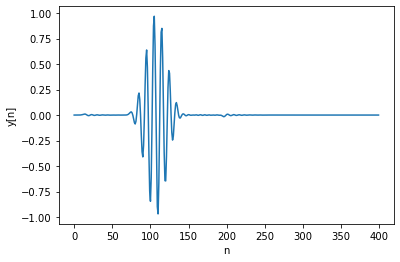

In [57]:
N = 400 # total number of samples in the input signal  
M =60 # size of the window function (and sample length of the frequency
n = np.arange(0, M+1, 1) # index vector of M+1 points  
wn = 0.54-0.46*np.cos(2*np.pi*n/M) # window function (Hamming window)  
# the components  
x1 = wn*np.cos(0.2*np.pi*n) # component with w1 = 0.2*pi frequency  
x2 = wn*np.cos(0.4*np.pi*n - np.pi/2) # component with w1 = 0.4*pi frequency  
x3 = wn*np.cos(0.8*np.pi*n - np.pi/5) # component with w1 = 0.8*pi frequency  
xn = np.concatenate((x3, x1, x2, np.zeros(N-3*len(n))), axis=None)  
plt.figure()
plt.plot(xn)
plt.show()

# importing an IIR filter  
filter_data = loadmat('lowpass_butterworth.mat') # load the filter obtained from  pyfda  
Coeffs = filter_data['ba'].astype(float) # get the coefficients and  <convert them to float (from string)  
#print(Coeffs)
b = Coeffs[:,0] # first column is b  
a = Coeffs[:,1]


w, Hw = sgnl.freqz(b,a)  
N = len(Hw)*2 #! Hw nin 0 ve arası alındığından uzunluğu 2 ile çarpılır bu da fourierinin uzunluğuna karşı gelmektedir
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, Hw_mag)  , plt.ylabel("unit")
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()



w, Hw = sgnl.freqz(b,a)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, 20*np.log10(Hw_mag))  , plt.ylabel("db")
plt.ylim([-80,10])
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()

tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.ylim([0,40])
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()


yn = sgnl.lfilter(b,a,xn) 
plt.figure()
plt.ylabel('y[n]')
plt.xlabel('n')
plt.plot(yn)
plt.show()




Filtre bir alçak geçirendir 0.3pi frekansının altındaki sinaylleri geçirmektedir. Ama fazı linear değildir . Farklı faza sahip bileşenle olsaydı sinaylde karışıma ve bozulmaya neden olabilirdi yine burda yaklaşık 10 15 arası bir gecikme bulunmakatadır.

### Bant geçiren IIR filtre tasarımı



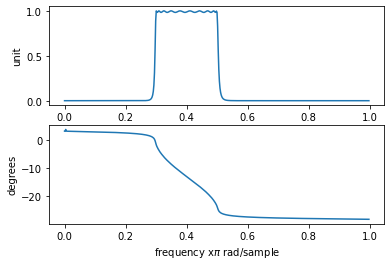

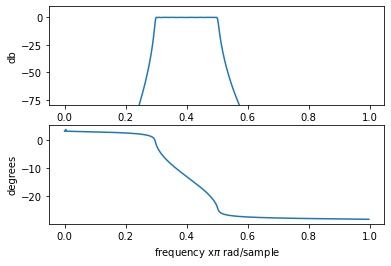

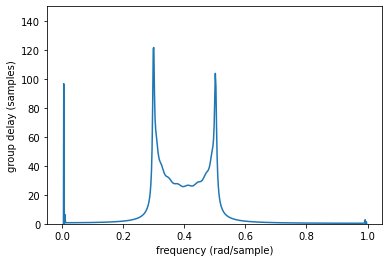

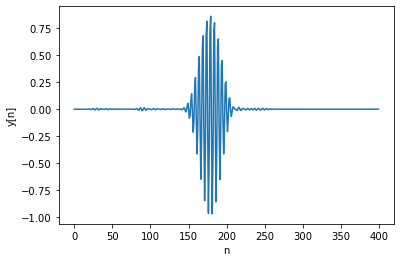

In [50]:
# As usual, we begin with importing necessary libraries and functions  
import numpy as np # for using basic array functions  
import matplotlib.pyplot as plt # for this example, it may not be necessary  
# the main package for signal processing is called "scipy" and we will use "signal" sub-package  
import scipy.signal as sgnl  
from scipy.fftpack import fft, ifft  
# alternative syntax: from scipy import signal as sgnl  
# to read .csv data file  
from scipy.io import loadmat  

# importing an IIR filter  
filter_data = loadmat('bandpass_chebyshev1.mat') # load the filter obtained from  pyfda  
Coeffs = filter_data['ba'].astype(float) # get the coefficients and  <convert them to float (from string)  
#print(Coeffs)
b = Coeffs[:,0] # first column is b  
a = Coeffs[:,1]


w, Hw = sgnl.freqz(b,a)  
N = len(Hw)*2
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, Hw_mag)  , plt.ylabel("unit")
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()



w, Hw = sgnl.freqz(b,a)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, 20*np.log10(Hw_mag))  , plt.ylabel("db")
plt.ylim([-80,10])
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()

tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.ylim([0,150])
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()



yn = sgnl.lfilter(b,a,xn) 
plt.figure()
plt.ylabel('y[n]')
plt.xlabel('n')
plt.plot(yn)
plt.show()


Filtre bant geçirendir filtreden sadece 0.4pi frekansına sahip sinyal geçebilmektedir diğer sinayller ise sönümlenmektedir.